In [ ]:
!pip install gtts -q  # quiet install gtts

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 3.3 MB/s eta 0:00:00


In [ ]:
import numpy as np
import librosa, librosa.display
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import Audio, display, clear_output
from gtts import gTTS
from pydub import AudioSegment  # warning
from scipy.signal import resample, butter, lfilter

from google.colab import drive
drive.mount('/content/drive')

/usr/local/lib/python3.12/dist-packages/pydub/utils.py:300: SyntaxWarning: invalid escape sequence '\('
  m = re.match('([su]([0-9]{1,2})p?) \(([0-9]{1,2}) bit\)$', token)
/usr/local/lib/python3.12/dist-packages/pydub/utils.py:301: SyntaxWarning: invalid escape sequence '\('
  m2 = re.match('([su]([0-9]{1,2})p?)( \(default\))?$', token)
/usr/local/lib/python3.12/dist-packages/pydub/utils.py:310: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(flt)p?( \(default\))?$', token):
/usr/local/lib/python3.12/dist-packages/pydub/utils.py:314: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(dbl)p?( \(default\))?$', token):


#Manipolazione di una traccia audio text-to-speech

Autore: Giulia Ponassi, Matricola: 6145273

## Introduzione

L'obiettivo principale del progetto é mostrare come una traccia audio text-to-speech venga modificata tramite algoritmi che alterano la voce, senza renderla incomprensibile.

In questo pitch mi concentro sulla parte del progetto in cui ricreo effetti presenti nei videogiochi e/o nella vita di tutti i giorni.



In [ ]:
def tts_to_wav(text, filename="tts_output.wav"):
    tts = gTTS(text=text, lang="it")
    tts.save("temp.mp3")  # mp3 temporaneo

    sound = AudioSegment.from_mp3("temp.mp3")
    sound.export(filename, format="wav")

    return filename

In [ ]:
text = "Ciao a tutti, sono Giulia. Spero che la mia presentazione vi piaccia."
filename = "base_voice.wav"

tts_to_wav(text, filename)
y_base, sr_base = librosa.load(filename, sr=None)

Audio(y_base, rate=sr_base)

In [ ]:
def plot_analysis(y, sr, title="Analisi Audio"):
    plt.figure(figsize=(10, 8), layout='constrained')

    # Forma d'onda
    plt.subplot(2, 1, 1)
    librosa.display.waveshow(y, sr=sr, alpha=0.8)
    plt.title("Ampiezza nel tempo")
    plt.xlabel("Tempo (s)")
    plt.ylabel("Ampiezza")
    plt.ylim(-1.1, 1.1)

    # Spettrogramma
    plt.subplot(2, 1, 2)
    S = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
    librosa.display.specshow(S, sr=sr, x_axis='time', y_axis='log', cmap='magma')
    plt.colorbar(format="%+2.0f dB")
    plt.title("Spettrogramma")

    plt.suptitle(title, fontsize=16)
    plt.tight_layout
    plt.show()

## Animalese: il linguaggio di *Animal Crossing*

In [ ]:
#modifica velocità, parte del notebook completo
def change_speed(y, factor):
    if factor <= 0: factor = 1.0
    new_length = int(len(y) / factor)
    y_resampled = resample(y, new_length)
    return y_resampled

In [ ]:
# simula voce dei villager di Animal Crossing
def animalese(y, sr):
    y = change_speed(y, 2.4)

    seg_len = int(0.055 * sr)  # segmentazione in 'sillabe'
    gap_len = int(0.005 * sr)  # pausa tra una sillaba e l'altra

    new_y = []

    window = np.hanning(seg_len)

    for i in range(0, len(y), seg_len):
        chunk = y[i:i+seg_len]  # segmento corrente
        if len(chunk) == seg_len:
            chunk = chunk * window
            new_y.extend(chunk)
            new_y.extend(np.zeros(gap_len))
        elif len(chunk) > 0: # ultimo chunk < 0.055
            temp_win = np.hanning(len(chunk)) # finestra di hanning 'personalizzata'
            new_y.extend(chunk * temp_win)

    return np.array(new_y)

Nella serie di videogiochi *Animal Crossing* sei l'unico umano in un mondo con personaggi animali. Questi animali, con cui puoi interagire, hanno una parlata distinta da una velocità elevata, pitch alto e divisione sillabica.

Il gioco non manipola una registrazione vocale intera come fa il mio script: legge il testo del dialogo carattere per carattere, e ogni singola lettera è associata a un brevissimo file audio pre-registrato. Per creare la parola, incolla questi file insieme.

###Come ho creato l'effetto?

Per prima cosa, il segnale audio originale viene accelerato di 2.4 volte. Se aumentiamo la velocità di riproduzione, otteniamo automaticamente un innalzamento della frequenza. L'aumento del pitch ricrea la voce acuta e rapida.

Per creare l'effetto delle sillabe, nel codice definisco una **seg_len**, ossia la lunghezza del segmento, di circa 55 millisecondi e un **gap_len**, ossia una pausa, di 5 millisecondi.

All'interno del ciclo for, applico una finestra di Hanning (**np.hanning**) a ogni frammento. La finestra di Hanning smussa l'inizio e la fine di ogni segmento, portandoli gradualmente a zero: è come se fosse un fade-in e un fade-out applicato ad ogni segmento. La uso perchè quando taglio l'audio in segmenti per simulare le sillabe, non sempre la parte finale del segmento sarà 'in silenzio'. Se non la usassi, tra ogni sillaba si creerebbe un disturbo fastidioso.

Infine, l'array new_y viene costruito alternando questi segmenti smussati a brevi pause di silenzio (**np.zeros(gap_len)**). L'elif gestisce l'ultimo segmento dell'audio, che potrebbe quindi essere più corto di 55 millisecondi, creando una finestra di hanning della sua lunghezza.




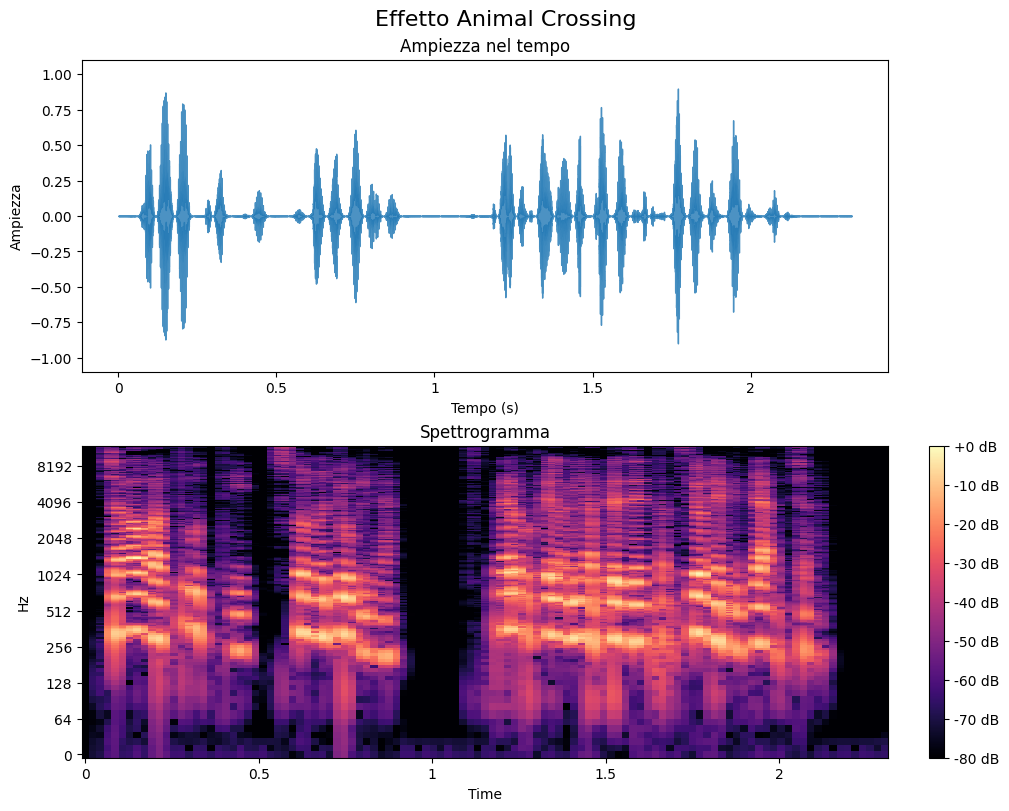

In [ ]:
if filename:
    y_base, sr_base = librosa.load(filename, sr=None)

    y_animalcrossing = animalese(y_base, sr_base)

    y_animalcrossing = y_animalcrossing / (np.max(np.abs(y_animalcrossing)) + 0.001) * 0.9

    display(Audio( y_animalcrossing, rate=sr_base))
    plot_analysis(y_animalcrossing, sr_base, f"Effetto Animal Crossing")

else:
    print("Errore: Variabili 'y' e 'sr' non trovate.")

##Radio: effetto ricetrasmettitore

In [ ]:
def radio(y, sr, noise_level=0.005):
    def butter_bandpass(lowcut, highcut, fs, order=5):
        nyq = 0.5 * fs  # fs/2
        low = lowcut / nyq
        high = highcut / nyq
        b, a = butter(order, [low, high], btype='band')
        return b, a

    def bandpass_filter(data, lowcut, highcut, fs, order=5):
        b, a = butter_bandpass(lowcut, highcut, fs, order=order)
        y = lfilter(b, a, data)
        return y

    y_filtered = bandpass_filter(y, 300, 3400, sr, order=6) # applico passabanda

    noise = np.random.normal(0, 1, len(y_filtered)) # rumore bianco
    y_noisy = y_filtered + (noise * noise_level)

    y_out = np.tanh(y_noisy * 2) # distorsione

    return y_out

Questo algoritmo vuole replicare l'effetto delle radio ricetrasmittenti, dei walkie-talkie.

Uso un filtro Butterworth, configurato come Passa-Banda tra i 300 Hz e i 3400 Hz. Questo perchè, in telefonia, la banda di frequenze per la voce è compresa approssimativamente tra 300 Hz e 3400 Hz.

Uso un filtro Butterworth perchè ha una finestra tendente al rettangolare che taglia via i bassi (sotto i 300Hz) e gli acuti (sopra i 3400Hz) in modo più netto rispetto, ad esempio, ad un filtro Gaussiano, che ha una discesa più graduale.

Il filtro Butterworth è ideale per isolare segnali con determinate frequenze e rimuovere quelle indesiderate.

###Come ho creato l'effetto?

Quando creo il filtro Butterworth, inizio calcolando la Frequenza di Nyquist: secondo il teorema del campionamento, l’ampiezza del periodo nelle frequenze è duale all’ampiezza del periodo nel tempo. Quindi, la massima frequenza gestibile è sempre la metà della frequenza di campionamento ($fs / 2$).

Devo poi dividere le frequenze che voglio usare come limite con quest'ultima: le funzioni di filtro digitale non usano gli Hz, ma vogliono un numero tra 0.0 e 1.0, dove 1.0 è la frequenza di Nyquist. In questo modo converto i limiti 300Hz e 3400Hz in questa scala che va da 0 a 1.

La funzione **butter**, della libreria scipy.signal, serve a progettare il filtro Butterworth.
La funzione restituisce i coefficienti del numeratore (b) e del denominatore (a) della funzione di trasferimento del filtro, che vengono usati per applicare il filtro al segnale.
L'ordine determina la ripidità del taglio del filtro: un ordine maggiore rende il taglio più ripido.

I sistemi analogici soffrono di interferenze che nel codice simulo aggiungendo Rumore Bianco Gaussiano (**np.random.normal**). Questo crea un array di numeri casuali della stessa lunghezza del segnale audio.

Infine, aggiungo una leggera distorsione. Per farlo, uso **np.tanh**. La funzione tangente iperbolica mappa qualsiasi input in un intervallo compreso tra -1 e +1.

L'effetto sul segnale audio si divide in due fasi, dipendenti dall'ampiezza dell'input:
- quando l'input $x$ è vicino allo zero, la funzione si comporta quasi linearmente: $\tanh(x) \approx x$. I suoni deboli passano quasi inalterati.
- man mano che l'input $x$ cresce, la curva smette di salire linearmente e inizia a piegarsi per avvicinarsi a $1$ (o $-1$ per valori negativi) senza mai superarlo.

Moltiplicare il segnale per 2 prima di applicare la funzione (**y_noisy * 2**) equivale ad alzare il gain, il guadagno, in ingresso, ***forzando volontariamente il segnale verso la zona non-lineare della curva***. Questo processo fa in modo che i suoni forti vengono limitati, mentre i suoni deboli vengono amplificati. Il risultato è un suono più denso, "sporco".


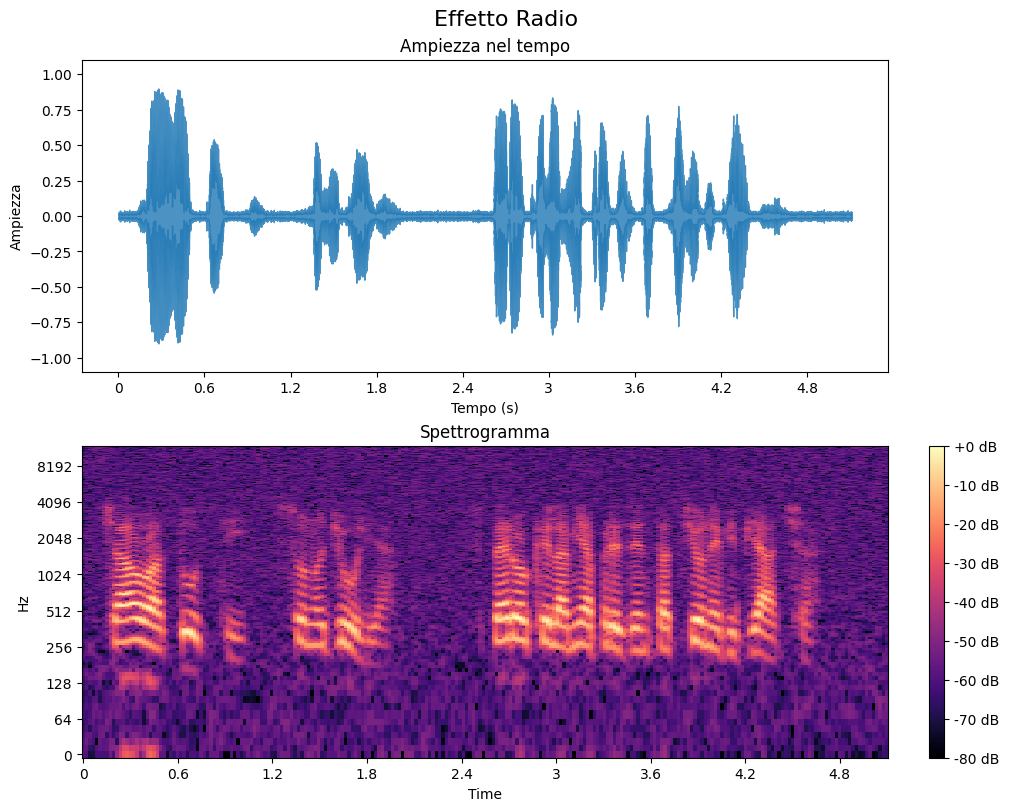

In [ ]:
if filename:
    y_base, sr_base = librosa.load(filename, sr=None)

    y_radio = radio(y_base, sr_base)

    y_radio = y_radio / (np.max(np.abs(y_radio)) + 0.001) * 0.9

    display(Audio( y_radio, rate=sr_base))
    plot_analysis(y_radio, sr_base, f"Effetto Radio")

else:
    print("Errore: Variabili 'y' e 'sr' non trovate.")

## Conclusioni del Pitch

###Cosa ho imparato?

Durante lo sviluppo di questo progetto, ho approfondito come l'elaborazione dei segnali possano alterare radicalmente la percezione di una voce.

Ho imparato a utilizzare la libreria scipy.signal per progettare filtri. Ho capito l'importanza della frequenza di Nyquist per convertire le frequenze reali in valori normalizzati utilizzabili dagli algoritmi. Inoltre, ho appreso come i filtri Butterworth siano essenziali per isolare bande di frequenza specifiche.

###Cosa non ha funzionato?

Durante la sperimentazione, ho dovuto scartare alcuni approcci iniziali che non restituivano i risultati sperati.

Nel filtro "Animal Crossing", non ho potuto usare dei file audio per ogni lettera dell'alfabeto come fa il gioco: ho quindi deciso di dividere l'audio creato in segmenti per simulare la divisione delle lettere. Ho anche notato che tagliare semplicemente l'audio in segmenti creava discontinuità udibili tra una "sillaba" e l'altra. Ho dovuto quindi implementare la Finestra di Hanning per smussare l'inizio e la fine di ogni frammento, eliminando i disturbi di transizione.

Per l'effetto "Radio", ho compreso che un filtro con andamento gaussiano non funzionava efficacemente: non tagliava nettamente i bassi e gli acuti come un vero dispositivo elettronico.